In [1]:
import Pkg; Pkg.activate("../.."); Pkg.instantiate()

  Activating project at `~/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim`


In [2]:
using Logging: global_logger
using TerminalLoggers: TerminalLogger
global_logger(TerminalLogger())

using ProgressLogging

In [3]:
using Plots, Revise, StaticArrays, Interpolations, LinearAlgebra

In [4]:
include("../../src/kf.jl")
include("../../src/ngpkf.jl")
include("../../src/SyntheticData.jl")
include("../../src/ergodic.jl")
include("../../src/simulator_spatial.jl")
include("../../src/TrajLib.jl")

Main.TrajectoryLibrary

In [5]:
# Define domain vars
dim = 100; # number of data points along each axis in the domain (defining a square domain)
xstart, xstop = 0, 25; # x-axis start and end positions
ystart, ystop = 0, 10; # y-axis start and end positions

σ_sq = 1.0
λₓ = 1/(4.0) 

env_data = SyntheticData.matern12_spatial(dim, xstart, xstop, ystart, ystop, σ_sq, λₓ);
# heatmap(range(xstart, stop=xstop, length=dim), range(ystart, stop=ystop, length=dim), env_data; c = :vik)
# title!("Synthetic Data: σ² = $(σ_sq), λₓ = $(λₓ)")

In [6]:
plotly();
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
plot!(clims=(-2,2))

┌ Warning: Failed to load integration with PlotlyBase & PlotlyKaleido.
│   exception =
│    ArgumentError: Package PlotlyBase not found in current path.
│    - Run `import Pkg; Pkg.add("PlotlyBase")` to install the PlotlyBase package.
│    Stacktrace:
│      [1] macro expansion
│        @ Base ./loading.jl:1766 [inlined]
│      [2] macro expansion
│        @ Base ./lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base ./loading.jl:1747
│      [4] #invoke_in_world#3
│        @ Base ./essentials.jl:921 [inlined]
│      [5] invoke_in_world
│        @ Base ./essentials.jl:918 [inlined]
│      [6] require(into::Module, mod::Symbol)
│        @ Base ./loading.jl:1740
│      [7] top-level scope
│        @ ~/.julia/packages/Plots/ju9dp/src/backends.jl:565
│      [8] eval
│        @ ./boot.jl:385 [inlined]
│      [9] _initialize_backend(pkg::Plots.PlotlyBackend)
│        @ Plots ~/.julia/packages/Plots/ju9dp/src/backends.jl:564
│     [10] backend
│        @ Plots 

In [7]:
# Create an ngpkf grid based on the data
σ_spatial = σ_sq
l_spatial = 1/λₓ

res_factor = 0.4 #l_spatial / sqrt(2.0)

kern = NGPKF.MaternKernel(σ_spatial, l_spatial)

ngp_grid_x = range(extrema(env_data.X)..., step= res_factor )
ngp_grid_y = range(extrema(env_data.Y)..., step= res_factor )



# ngp_grid_x = range(extrema(env_data.X)..., length=10) # step= res_factor )
# ngp_grid_y = range(extrema(env_data.Y)..., length=10)# step= res_factor )

0.0:0.4:10.0

In [8]:
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)


Main.NGPKF.NGPKFGrid{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{SVector{2, Float64}}, Hermitian{Float64, Matrix{Float64}}, Main.NGPKF.MaternKernel{Float64}}(0.0:0.4:24.8, 0.0:0.4:10.0, SVector{2, Float64}[[0.0, 0.0], [0.4, 0.0], [0.8, 0.0], [1.2, 0.0], [1.6, 0.0], [2.0, 0.0], [2.4, 0.0], [2.8, 0.0], [3.2, 0.0], [3.6, 0.0]  …  [21.2, 10.0], [21.6, 10.0], [22.0, 10.0], [22.4, 10.0], [22.8, 10.0], [23.2, 10.0], [23.6, 10.0], [24.0, 10.0], [24.4, 10.0], [24.8, 10.0]], Main.NGPKF.MaternKernel{Float64}(1.0, 2.0), [4.290430134802369 -2.119200638497972 … 5.75147549774901e-11 1.2157190600028422e-10; -2.119200638497972 5.690706754073149 … 2.440908094009869e-11 5.751475498359103e-11; … ; 5.75147549774901e-11 2.440908094009869e-11 … 5.690706754073153 -2.1192006384979614; 1.2157190600028422e-10 5.751475498359103e-11 … -2.1192006384979614 4.2904301348023575])

In [9]:
@assert maximum(abs.(ngpkf_grid.invK)) < 10.0

In [10]:
x0s = [@SVector[rand(ngpkf_grid.xs[2:(end-2)]), rand(ngpkf_grid.ys[2:(end-2)])] for i=1:1]


1-element Vector{SVector{2, Float64}}:
 [4.0, 8.0]

In [11]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
scatter!(first.(x0s), last.(x0s))
plot!(clims=(-2,2))

In [12]:
1.0
1
ΔT = 5.0 / 60.0 # seconds
2
Tend = 1.0 # hours 
3
ts = 0.0:(ΔT):(Tend * 60)


0.0:0.08333333333333333:60.0

In [13]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(ΔT)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

DxS (generic function with 1 method)

In [14]:
using DifferentialEquations
using ForwardDiff

function clarity_prediction(t, q0, C, R, Q)

    k = C / sqrt(Q * R)
    
    q∞ = k / (1 + k)

    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
end

    
function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
    println("q0: $(q0)")
    println("qf: $(qf)")
    println("C: $(C)")
    println("R: $(R)")
    println("Q: $(Q)")
    
    if q0 >= qf
        return 0.0
    end

    k = C / sqrt(Q * R)
    println("k: $(k)")
    
    q∞ = k / (1 + k)
    println("q∞: $(q∞)")
    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    
        
    if qf >= q∞
        return tmax
    end

    t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
    println("t: $(t)")

    return min(t, tmax)
end

C = 1.0
R = 0.5
Q = 0.0
Clarity_decay(u,p,t) = (C^2 / R) * (1-u)^2 - Q * u^2


function Forward_Simulate_Clarity(current_clarity, target_clarity; fn::Function = Clarity)
    """
    Forward simulate for maximum 10 seconds
    Here for now I only consider the spatiostatic environment 
    """    
    tspan = (0.0, 10.0) # 10 is just chosen to be a huge value for this problem
    u0 = current_clarity
    prob = ODEProblem(fn, u0, tspan)
    condition(u, t, integrator) = u ≥ target_clarity
    affect!(integrator) = terminate!(integrator)
    cb = DiscreteCallback(condition, affect!)
    sol = solve(prob, Tsit5(), callback = cb);
    return sol.t[end]
    
end

Forward_Simulate_Clarity (generic function with 1 method)

In [15]:
 δt = Forward_Simulate_Clarity(0.5, 0.9; fn = Clarity_decay)

4.941428437228555

In [16]:
using LinearAlgebra, StatsBase

function ergo_controller3(t, xs; 
        ergo_grid,
        ergo_q_map,
        traj,
        umax=30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )

    target_q = 0.8 ; # * ones(size(ergo_q_map))

    target_spatial_dist = zeros(size(ergo_q_map))

    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))

    C_ = Cfun(0,0)
    R_ = Rfun(0,0)
    
#     println("ergo_q_map: $(ergo_q_map)")
    
    for i in CartesianIndices(target_spatial_dist)
        if target_q > ergo_q_map[i]
            target_spatial_dist[i] = Forward_Simulate_Clarity(ergo_q_map[i], target_q; fn = Clarity_decay)
        else
            target_spatial_dist[i] = 0.0
        end
#         target_spatial_dist[i] = clarity_time(ergo_q_map[i], target_q, C_, R_, Qp)
        

    end
    
#     println("target_spatial_dist: $(target_spatial_dist)")
    # Remove Nans
    
#     for cell in CartesianIndices(target_spatial_dist)
#         if isnan(target_spatial_dist[cell])
#             target_spatial_dist[cell] = 0
#         else 
#             target_spatial_dist[cell] = max(0, target_spatial_dist[cell])
#         end
#     end
        
    u = [ErgodicController.controller_single_integrator(ergo_grid, x, traj, target_spatial_dist; umax=umax) for x in xs]
    return u

end

ergo_controllers3 = [ergo_controller3 for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller3)}:
 ergo_controller3 (generic function with 1 method)

In [17]:
ΔT = 5.0/60.0 # minutes
# Tend = 0.1 # hours 
ts = 0.0:(ΔT):(75)
fuse_measurements_every_ΔT = 5.0 # minutes
recompute_controller_every_ΔT = 5.0 / 60.0 # minutes
σ_t = zeros(63, 26);

In [18]:
@time res_ergo =  SimulatorSpatial.simulate_spatial(ts, x0s, ergo_controller3; 
    ngpkf_grid=ngpkf_grid, 
    EnvDataSpatial=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:22:45
Progress:   1%|▌                                        |  ETA: 0:21:06
Progress:   2%|▋                                        |  ETA: 0:20:25
Progress:   2%|▉                                        |  ETA: 0:20:07
Progress:   3%|█▏                                       |  ETA: 0:19:49
Progress:   3%|█▍                                       |  ETA: 0:19:35
Progress:   4%|█▋                                       |  ETA: 0:19:25
Progress:   4%|█▉                                       |  ETA: 0:19:12
Progress:   5%|██                                       |  ETA: 0:19:03
Progress:   6%|██▎                                      |  ETA: 0:18:55
Progress:   6%|██▌                                      |  ETA: 0:18:46


Inside prediction of NGP


Progress:   7%|██▊                                      |  ETA: 0:18:37
Progress:   7%|███                                      |  ETA: 0:18:40
Progress:   8%|███▎                                     |  ETA: 0:18:30
Progress:   8%|███▍                                     |  ETA: 0:18:20
Progress:   9%|███▋                                     |  ETA: 0:18:09
Progress:   9%|███▉                                     |  ETA: 0:18:00
Progress:  10%|████▏                                    |  ETA: 0:17:49
Progress:  11%|████▍                                    |  ETA: 0:17:39
Progress:  11%|████▌                                    |  ETA: 0:17:28
Progress:  12%|████▊                                    |  ETA: 0:17:18
Progress:  12%|█████                                    |  ETA: 0:17:09
Progress:  13%|█████▎                                   |  ETA: 0:16:59


Inside prediction of NGP


Progress:  13%|█████▌                                   |  ETA: 0:16:50
Progress:  14%|█████▊                                   |  ETA: 0:16:41
Progress:  14%|█████▉                                   |  ETA: 0:16:31
Progress:  15%|██████▏                                  |  ETA: 0:16:21
Progress:  16%|██████▍                                  |  ETA: 0:16:11
Progress:  16%|██████▋                                  |  ETA: 0:16:02
Progress:  17%|██████▉                                  |  ETA: 0:15:53
Progress:  17%|███████                                  |  ETA: 0:15:44
Progress:  18%|███████▎                                 |  ETA: 0:15:36
Progress:  18%|███████▌                                 |  ETA: 0:15:28
Progress:  19%|███████▊                                 |  ETA: 0:15:20
Progress:  19%|████████                                 |  ETA: 0:15:13


...

Inside prediction of NGP


Progress:  93%|██████████████████████████████████████▎  |  ETA: 0:01:00
Progress:  94%|██████████████████████████████████████▌  |  ETA: 0:00:55
Progress:  94%|██████████████████████████████████████▊  |  ETA: 0:00:50
Progress:  95%|███████████████████████████████████████  |  ETA: 0:00:45
Progress:  96%|███████████████████████████████████████▏ |  ETA: 0:00:40
Progress:  96%|███████████████████████████████████████▍ |  ETA: 0:00:35
Progress:  97%|███████████████████████████████████████▋ |  ETA: 0:00:30
Progress:  97%|███████████████████████████████████████▉ |  ETA: 0:00:25
Progress:  98%|████████████████████████████████████████▏|  ETA: 0:00:20
Progress:  98%|████████████████████████████████████████▍|  ETA: 0:00:15
Progress:  99%|████████████████████████████████████████▌|  ETA: 0:00:10
Progress:  99%|████████████████████████████████████████▊|  ETA: 0:00:05


884.789655 seconds (29.75 G allocations: 674.456 GiB, 5.43% gc time, 0.42% compilation time)


Progress: 100%|█████████████████████████████████████████| Time: 0:14:41
Progress: 100%|█████████████████████████████████████████| Time: 0:14:41


Main.SimulatorSpatial.SimResult{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(0.0:0.08333333333333333:75.0, Vector{SVector{2, Float64}}[[[4.0, 8.0]], [[4.139868388962972, 7.945807438066623]], [[4.281294137036651, 7.895819861792113]], [[4.413449712902934, 7.824862805994601]], [[4.537024622883552, 7.739837858930329]], [[4.654492610558524, 7.64655725070122]], [[4.767137162351893, 7.547505723952406]], [[4.8726995856944475, 7.4409384926941655]], [[4.97300177540127, 7.3294061173943605]], [[5.070172652900114, 7.215135296245195]]  …  [[4.116701806961462, 1.233863757264666]], [[4.253785473579888, 1.172969846678728]], [[4.391369744682663, 1.1132156138151217]], [[4.527

In [19]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo.xs]
    y = [r[i][2] for r in res_ergo.xs]
    plot!(x, y, linewidth=3, color=:black)
end
plot!()

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
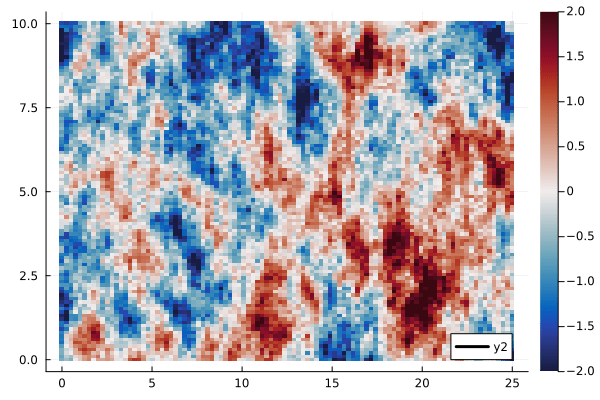

In [20]:
gr()
@gif for n = Int.(floor.(range(1, length(res_ergo.xs), length=420)))
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo.xs[1:n]]
        y = [r[i][2] for r in res_ergo.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
end

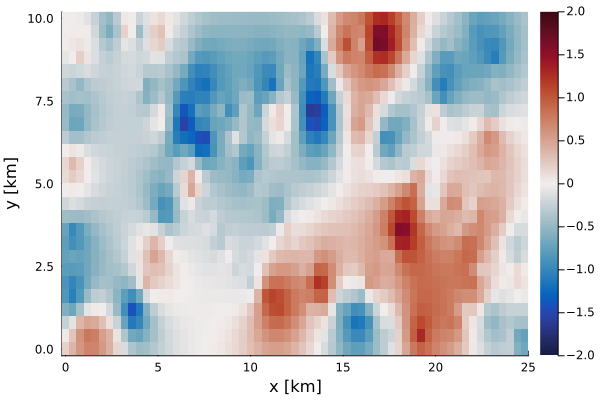

In [21]:
gr()

p2 = heatmap(ngpkf_grid, res_ergo.w_hats[end],colormap=:balance, clims=(-2,2))

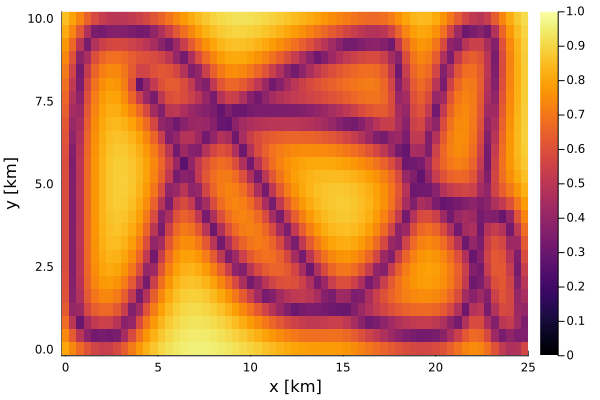

In [22]:
p2 = heatmap(ngpkf_grid, res_ergo.w_hats[end], clims=(0, 1.0), plotstd=true)
# for i=1:length(x0s)
#     x = [r[i][1] for r in res_ergo.xs]
#     y = [r[i][2] for r in res_ergo.xs]
#     plot!(x, y, linewidth=3)
# end
plot!()

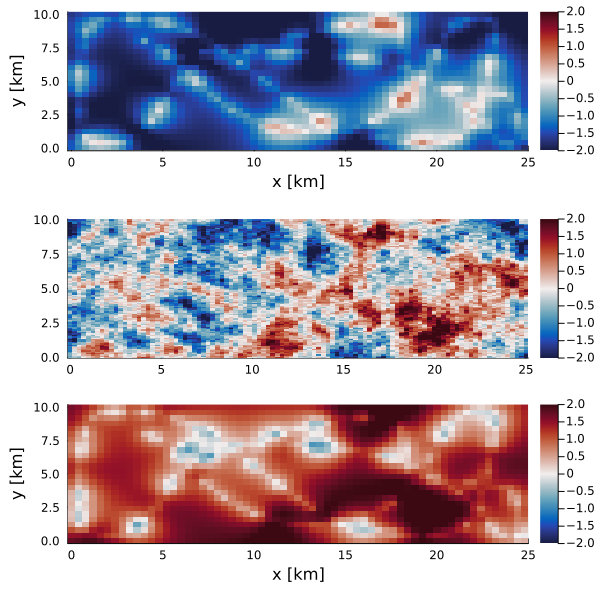

In [23]:
gr()

p1 = heatmap(ngpkf_grid, res_ergo.w_hats[end],colormap=:balance, clims=(-2,2), plot_min=true)
p2 = heatmap(ngpkf_grid, res_ergo.w_hats[end],colormap=:balance, clims=(-2,2), plot_max=true)
p3 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
    
plot(p1, p3, p2, layout = (@layout [a;b; c]), size=[600, 600])

In [24]:
# rmse and precision 

Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)

M = reshape(KF.μ(res_ergo.w_hats[end]), Nx, Ny)
heatmap(M',colormap=:balance, clims=(-2,2) )
x_new = 0:0.4:25
y_new = 0:0.4:10
Data_sampled = [env_data.itp_w(xi, yi) for yi in y_new, xi in x_new]
Diff = M' .- Data_sampled
rmse_2_2 = sqrt(mean(Diff .^ 2))

0.5721526131747593

In [25]:
# Compute Precision

σ_prec = KF.σ(res_ergo.w_hats[end])
M_prec = reshape(σ_prec, Nx, Ny)
precision_2_2 = sum(M_prec)/length(M_prec)

0.6080351864533334

## Generate trajectory for the for 10 and use it over 2



In [26]:
# Define domain vars
dim = 100; # number of data points along each axis in the domain (defining a square domain)
xstart, xstop = 0, 25; # x-axis start and end positions
ystart, ystop = 0, 10; # y-axis start and end positions

σ_sq_10 = 1.0
λₓ_10 = 1/(10.0) 

env_data_10 = SyntheticData.matern12_spatial(dim, xstart, xstop, ystart, ystop, σ_sq_10, λₓ_10);
# heatmap(range(xstart, stop=xstop, length=dim), range(ystart, stop=ystop, length=dim), env_data; c = :vik)
# title!("Synthetic Data: σ² = $(σ_sq), λₓ = $(λₓ)")

In [27]:
# Create an ngpkf grid based on the data
σ_spatial_10 = σ_sq_10
l_spatial_10 = 1/λₓ_10

res_factor = 0.4 #l_spatial / sqrt(2.0)

kern_10 = NGPKF.MaternKernel(σ_spatial_10, l_spatial_10)

ngp_grid_x_10 = range(extrema(env_data_10.X)..., step= res_factor )
ngp_grid_y_10 = range(extrema(env_data_10.Y)..., step= res_factor )



# ngp_grid_x = range(extrema(env_data.X)..., length=10) # step= res_factor )
# ngp_grid_y = range(extrema(env_data.Y)..., length=10)# step= res_factor )

0.0:0.4:10.0

In [28]:
ngpkf_grid_10 = NGPKF.NGPKFGrid(ngp_grid_x_10, ngp_grid_y_10, kern_10)

Main.NGPKF.NGPKFGrid{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{SVector{2, Float64}}, Hermitian{Float64, Matrix{Float64}}, Main.NGPKF.MaternKernel{Float64}}(0.0:0.4:24.8, 0.0:0.4:10.0, SVector{2, Float64}[[0.0, 0.0], [0.4, 0.0], [0.8, 0.0], [1.2, 0.0], [1.6, 0.0], [2.0, 0.0], [2.4, 0.0], [2.8, 0.0], [3.2, 0.0], [3.6, 0.0]  …  [21.2, 10.0], [21.6, 10.0], [22.0, 10.0], [22.4, 10.0], [22.8, 10.0], [23.2, 10.0], [23.6, 10.0], [24.0, 10.0], [24.4, 10.0], [24.8, 10.0]], Main.NGPKF.MaternKernel{Float64}(1.0, 10.0), [20.16374102611437 -10.754348337771857 … 4.231306568563841e-5 0.00018657638033194772; -10.754348337771857 28.108451067849106 … 8.47477155893697e-6 4.2313065694128685e-5; … ; 4.231306568563841e-5 8.47477155893697e-6 … 28.108451067848986 -10.75434833777178; 0.00018657638033194772 4.2313065694128685e-5 … -10.75434833777178 20.16374102611436])

In [29]:
@time res_ergo_10 =  SimulatorSpatial.simulate_spatial(ts, x0s, ergo_controller3; 
    ngpkf_grid=ngpkf_grid_10, 
    EnvDataSpatial=env_data_10, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:18:27
Progress:   1%|▌                                        |  ETA: 0:18:16
Progress:   2%|▋                                        |  ETA: 0:18:06
Progress:   2%|▉                                        |  ETA: 0:17:58
Progress:   3%|█▏                                       |  ETA: 0:17:52
Progress:   3%|█▍                                       |  ETA: 0:17:46
Progress:   4%|█▋                                       |  ETA: 0:17:40
Progress:   4%|█▉                                       |  ETA: 0:17:34
Progress:   5%|██                                       |  ETA: 0:17:29
Progress:   6%|██▎                                      |  ETA: 0:17:23
Progress:   6%|██▌                                      |  ETA: 0:17:17


Inside prediction of NGP


Progress:   7%|██▊                                      |  ETA: 0:17:13
Progress:   7%|███                                      |  ETA: 0:16:55
Progress:   8%|███▎                                     |  ETA: 0:16:35
Progress:   8%|███▍                                     |  ETA: 0:16:15
Progress:   9%|███▋                                     |  ETA: 0:15:57
Progress:   9%|███▉                                     |  ETA: 0:15:40
Progress:  10%|████▏                                    |  ETA: 0:15:24
Progress:  11%|████▍                                    |  ETA: 0:15:10
Progress:  11%|████▌                                    |  ETA: 0:14:57
Progress:  12%|████▊                                    |  ETA: 0:14:45
Progress:  12%|█████                                    |  ETA: 0:14:34
Progress:  13%|█████▎                                   |  ETA: 0:14:22


Inside prediction of NGP


Progress:  13%|█████▌                                   |  ETA: 0:14:11
Progress:  14%|█████▊                                   |  ETA: 0:13:57
Progress:  14%|█████▉                                   |  ETA: 0:13:41
Progress:  15%|██████▏                                  |  ETA: 0:13:27
Progress:  16%|██████▍                                  |  ETA: 0:13:14
Progress:  16%|██████▋                                  |  ETA: 0:13:02
Progress:  17%|██████▉                                  |  ETA: 0:12:49
Progress:  17%|███████                                  |  ETA: 0:12:37
Progress:  18%|███████▎                                 |  ETA: 0:12:26
Progress:  18%|███████▌                                 |  ETA: 0:12:15
Progress:  19%|███████▊                                 |  ETA: 0:12:04
Progress:  19%|████████                                 |  ETA: 0:11:54


...

Inside prediction of NGP


Progress:  93%|██████████████████████████████████████▎  |  ETA: 0:00:25
Progress:  94%|██████████████████████████████████████▌  |  ETA: 0:00:23
Progress:  94%|██████████████████████████████████████▊  |  ETA: 0:00:21
Progress:  95%|███████████████████████████████████████  |  ETA: 0:00:18
Progress:  96%|███████████████████████████████████████▏ |  ETA: 0:00:16
Progress:  96%|███████████████████████████████████████▍ |  ETA: 0:00:14
Progress:  97%|███████████████████████████████████████▋ |  ETA: 0:00:12
Progress:  97%|███████████████████████████████████████▉ |  ETA: 0:00:10
Progress:  98%|████████████████████████████████████████▏|  ETA: 0:00:08
Progress:  98%|████████████████████████████████████████▍|  ETA: 0:00:06
Progress:  99%|████████████████████████████████████████▌|  ETA: 0:00:04


351.210557 seconds (11.53 G allocations: 277.739 GiB, 5.31% gc time)


Progress:  99%|████████████████████████████████████████▊|  ETA: 0:00:02
Progress: 100%|█████████████████████████████████████████| Time: 0:05:49
Progress: 100%|█████████████████████████████████████████| Time: 0:05:49


Main.SimulatorSpatial.SimResult{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(0.0:0.08333333333333333:75.0, Vector{SVector{2, Float64}}[[[4.0, 8.0]], [[4.139868388962972, 7.945807438066623]], [[4.281294137036652, 7.895819861792113]], [[4.413449712902935, 7.824862805994601]], [[4.5370246228835525, 7.739837858930329]], [[4.654492610558525, 7.64655725070122]], [[4.767137162351894, 7.547505723952406]], [[4.872699585694448, 7.4409384926941655]], [[4.973001775401271, 7.3294061173943605]], [[5.070172652900115, 7.215135296245195]]  …  [[6.136361201565177, 4.784862991422515]], [[6.286360954563681, 4.785135205286826]], [[6.436360819245683, 4.7849337223322665]], [[6.58

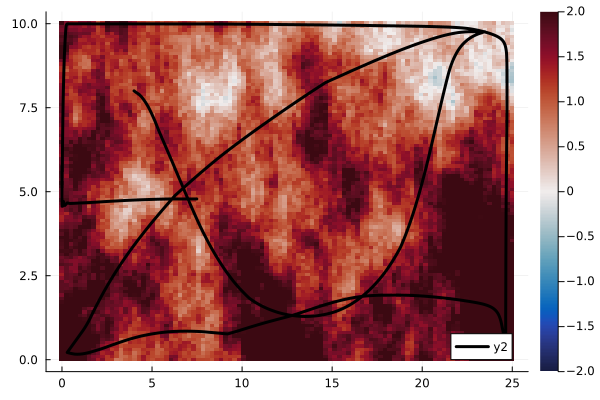

In [30]:
plot()
heatmap(env_data_10.X, env_data_10.Y, env_data_10.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo_10.xs]
    y = [r[i][2] for r in res_ergo_10.xs]
    plot!(x, y, linewidth=3, color=:black)
end
plot!()

In [31]:
# rmse and precision 

Nx_10, Ny_10 = length(ngpkf_grid_10.xs), length(ngpkf_grid_10.ys)

M_10 = reshape(KF.μ(res_ergo_10.w_hats[end]), Nx_10, Ny_10)
heatmap(M_10',colormap=:balance, clims=(-2,2) )
x_new = 0:0.4:25
y_new = 0:0.4:10
Data_sampled_10 = [env_data_10.itp_w(xi, yi) for yi in y_new, xi in x_new]
Diff_10 = M_10' .- Data_sampled_10
rmse_2_2 = sqrt(mean(Diff_10 .^ 2))

0.33987938732313233

In [32]:
# Compute Precision

σ_prec_10 = KF.σ(res_ergo_10.w_hats[end])
M_prec_10 = reshape(σ_prec_10, Nx_10, Ny_10)
precision_10_10 = sum(M_prec_10)/length(M_prec_10)

0.3304358064303462

### Trajectory of length scale 10 over 2

In [33]:
# Trajectory of 0.1 length scale  over 10
@time res_10over2 =  SimulatorSpatial.simulate_prerec_traj(ts, res_ergo_10.xs; 
    ngpkf_grid=ngpkf_grid, 
    EnvDataSpatial=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Inside prediction of NGP


Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:00:00
Progress:   1%|▌                                        |  ETA: 0:00:00
Progress:   2%|▋                                        |  ETA: 0:00:00
Progress:   2%|▉                                        |  ETA: 0:00:00
Progress:   3%|█▏                                       |  ETA: 0:00:00
Progress:   3%|█▍                                       |  ETA: 0:00:00
Progress:   4%|█▋                                       |  ETA: 0:00:00
Progress:   4%|█▉                                       |  ETA: 0:00:00
Progress:   5%|██                                       |  ETA: 0:00:00
Progress:   6%|██▎                                      |  ETA: 0:00:00
Progress:   6%|██▌                                      |  ETA: 0:00:00
Progress:   7%|██▊                                      |  ETA: 0:00:00


Inside prediction of NGP


Progress:   7%|███                                      |  ETA: 0:00:04
Progress:   8%|███▎                                     |  ETA: 0:00:04
Progress:   8%|███▍                                     |  ETA: 0:00:03
Progress:   9%|███▋                                     |  ETA: 0:00:03
Progress:   9%|███▉                                     |  ETA: 0:00:03
Progress:  10%|████▏                                    |  ETA: 0:00:03
Progress:  11%|████▍                                    |  ETA: 0:00:03
Progress:  11%|████▌                                    |  ETA: 0:00:02
Progress:  12%|████▊                                    |  ETA: 0:00:02
Progress:  12%|█████                                    |  ETA: 0:00:02
Progress:  13%|█████▎                                   |  ETA: 0:00:02
Progress:  13%|█████▌                                   |  ETA: 0:00:02


Inside prediction of NGP


...

Inside prediction of NGP


Progress:  87%|███████████████████████████████████▊     |  ETA: 0:00:01
Progress:  88%|████████████████████████████████████     |  ETA: 0:00:01
Progress:  88%|████████████████████████████████████▎    |  ETA: 0:00:01
Progress:  89%|████████████████████████████████████▌    |  ETA: 0:00:00
Progress:  89%|████████████████████████████████████▋    |  ETA: 0:00:00
Progress:  90%|████████████████████████████████████▉    |  ETA: 0:00:00
Progress:  91%|█████████████████████████████████████▏   |  ETA: 0:00:00
Progress:  91%|█████████████████████████████████████▍   |  ETA: 0:00:00
Progress:  92%|█████████████████████████████████████▋   |  ETA: 0:00:00
Progress:  92%|█████████████████████████████████████▊   |  ETA: 0:00:00
Progress:  93%|██████████████████████████████████████   |  ETA: 0:00:00
Progress:  93%|██████████████████████████████████████▎  |  ETA: 0:00:00


  4.566129 seconds (201.32 k allocations: 3.020 GiB, 0.58% gc time, 3.85% compilation time)


Progress:  94%|██████████████████████████████████████▌  |  ETA: 0:00:00
Progress:  94%|██████████████████████████████████████▊  |  ETA: 0:00:00
Progress:  95%|███████████████████████████████████████  |  ETA: 0:00:00
Progress:  96%|███████████████████████████████████████▏ |  ETA: 0:00:00
Progress:  96%|███████████████████████████████████████▍ |  ETA: 0:00:00
Progress:  97%|███████████████████████████████████████▋ |  ETA: 0:00:00
Progress:  97%|███████████████████████████████████████▉ |  ETA: 0:00:00
Progress:  98%|████████████████████████████████████████▏|  ETA: 0:00:00
Progress:  98%|████████████████████████████████████████▍|  ETA: 0:00:00
Progress:  99%|████████████████████████████████████████▌|  ETA: 0:00:00
Progress:  99%|████████████████████████████████████████▊|  ETA: 0:00:00
Progress: 100%|█████████████████████████████████████████| Time: 0:00:04
Progress: 100%|█████████████████████████████████████████| Time: 0:00:04


Main.SimulatorSpatial.SimResultPre{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(0.0:0.08333333333333333:75.0, Vector{SVector{2, Float64}}[[[4.0, 8.0]], [[4.139868388962972, 7.945807438066623]], [[4.281294137036652, 7.895819861792113]], [[4.413449712902935, 7.824862805994601]], [[4.5370246228835525, 7.739837858930329]], [[4.654492610558525, 7.64655725070122]], [[4.767137162351894, 7.547505723952406]], [[4.872699585694448, 7.4409384926941655]], [[4.973001775401271, 7.3294061173943605]], [[5.070172652900115, 7.215135296245195]]  …  [[6.136361201565177, 4.784862991422515]], [[6.286360954563681, 4.785135205286826]], [[6.436360819245683, 4.7849337223322665]], [[6.58636028398952, 4.78453300227717]], 

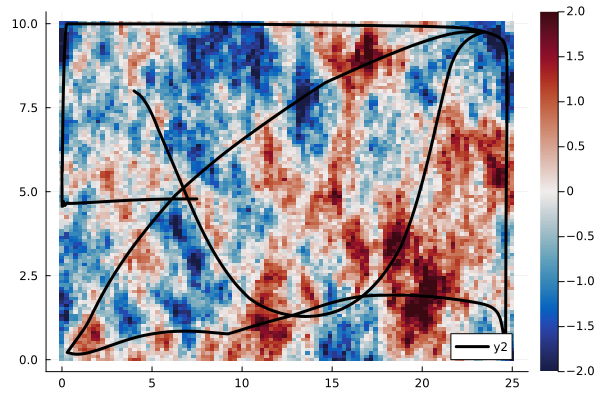

In [34]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
for i=1:length(x0s)
    x = [r[i][1] for r in res_10over2.xs]
    y = [r[i][2] for r in res_10over2.xs]
    plot!(x, y, linewidth=3, color=:black)
end
plot!()

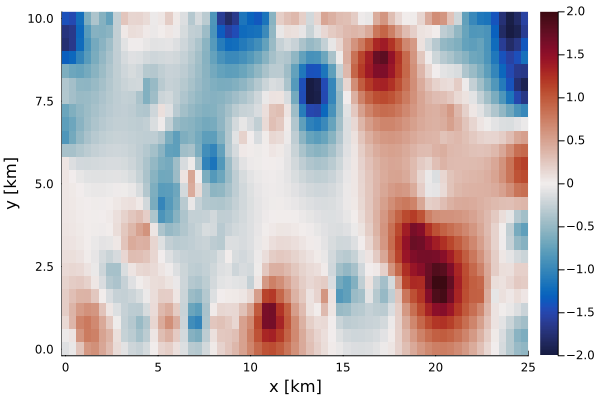

In [35]:
gr()

p2 = heatmap(ngpkf_grid, res_10over2.w_hats[end],colormap=:balance, clims=(-2,2))

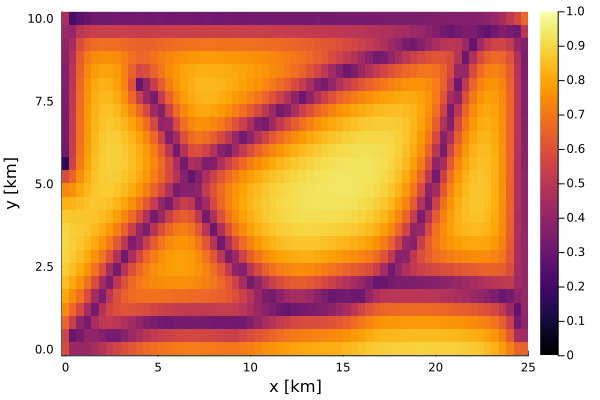

In [36]:
p2 = heatmap(ngpkf_grid, res_10over2.w_hats[end], clims=(0, 1.0), plotstd=true)
# for i=1:length(x0s)
#     x = [r[i][1] for r in res_ergo.xs]
#     y = [r[i][2] for r in res_ergo.xs]
#     plot!(x, y, linewidth=3)
# end
plot!()

In [37]:
# rmse and precision 

Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)

M_10_2 = reshape(KF.μ(res_10over2.w_hats[end]), Nx, Ny)
heatmap(M_10_2',colormap=:balance, clims=(-2,2) )
x_new = 0:0.4:25
y_new = 0:0.4:10
Data_sampled_10_2 = [env_data.itp_w(xi, yi) for yi in y_new, xi in x_new]
Diff_10_2 = M_10_2' .- Data_sampled_10_2
rmse_10_2 = sqrt(mean(Diff_10_2 .^ 2))

0.5761772087337644

In [38]:
# Compute Precision

σ_prec_10_2 = KF.σ(res_10over2.w_hats[end])
M_prec_10_2 = reshape(σ_prec_10_2, Nx, Ny)
precision_10_2 = sum(M_prec_10_2)/length(M_prec_10_2)

0.6406554265255038

In [ ]:
### Trajectory of length scale 2 over 10

In [39]:
# Trajectory of 0.1 length scale  over 10
@time res_2over10 =  SimulatorSpatial.simulate_prerec_traj(ts, res_ergo.xs; 
    ngpkf_grid=ngpkf_grid_10, 
    EnvDataSpatial=env_data_10, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Inside prediction of NGP


Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:00:00
Progress:   1%|▌                                        |  ETA: 0:00:00
Progress:   2%|▋                                        |  ETA: 0:00:00
Progress:   2%|▉                                        |  ETA: 0:00:00
Progress:   3%|█▏                                       |  ETA: 0:00:00
Progress:   3%|█▍                                       |  ETA: 0:00:00
Progress:   4%|█▋                                       |  ETA: 0:00:00
Progress:   4%|█▉                                       |  ETA: 0:00:00
Progress:   5%|██                                       |  ETA: 0:00:00
Progress:   6%|██▎                                      |  ETA: 0:00:00
Progress:   6%|██▌                                      |  ETA: 0:00:00
Progress:   7%|██▊                                      |  ETA: 0:00:00


Inside prediction of NGP


Progress:   7%|███                                      |  ETA: 0:00:04
Progress:   8%|███▎                                     |  ETA: 0:00:04
Progress:   8%|███▍                                     |  ETA: 0:00:03
Progress:   9%|███▋                                     |  ETA: 0:00:03
Progress:   9%|███▉                                     |  ETA: 0:00:03
Progress:  10%|████▏                                    |  ETA: 0:00:03
Progress:  11%|████▍                                    |  ETA: 0:00:03
Progress:  11%|████▌                                    |  ETA: 0:00:02
Progress:  12%|████▊                                    |  ETA: 0:00:02
Progress:  12%|█████                                    |  ETA: 0:00:02
Progress:  13%|█████▎                                   |  ETA: 0:00:02
Progress:  13%|█████▌                                   |  ETA: 0:00:02


Inside prediction of NGP


...

Inside prediction of NGP


Progress:  87%|███████████████████████████████████▊     |  ETA: 0:00:01
Progress:  88%|████████████████████████████████████     |  ETA: 0:00:01
Progress:  88%|████████████████████████████████████▎    |  ETA: 0:00:01
Progress:  89%|████████████████████████████████████▌    |  ETA: 0:00:01
Progress:  89%|████████████████████████████████████▋    |  ETA: 0:00:00
Progress:  90%|████████████████████████████████████▉    |  ETA: 0:00:00
Progress:  91%|█████████████████████████████████████▏   |  ETA: 0:00:00
Progress:  91%|█████████████████████████████████████▍   |  ETA: 0:00:00
Progress:  92%|█████████████████████████████████████▋   |  ETA: 0:00:00
Progress:  92%|█████████████████████████████████████▊   |  ETA: 0:00:00
Progress:  93%|██████████████████████████████████████   |  ETA: 0:00:00
Progress:  93%|██████████████████████████████████████▎  |  ETA: 0:00:00


  4.612784 seconds (33.19 k allocations: 3.009 GiB, 0.52% gc time)


Progress:  94%|██████████████████████████████████████▌  |  ETA: 0:00:00
Progress:  94%|██████████████████████████████████████▊  |  ETA: 0:00:00
Progress:  95%|███████████████████████████████████████  |  ETA: 0:00:00
Progress:  96%|███████████████████████████████████████▏ |  ETA: 0:00:00
Progress:  96%|███████████████████████████████████████▍ |  ETA: 0:00:00
Progress:  97%|███████████████████████████████████████▋ |  ETA: 0:00:00
Progress:  97%|███████████████████████████████████████▉ |  ETA: 0:00:00
Progress:  98%|████████████████████████████████████████▏|  ETA: 0:00:00
Progress:  98%|████████████████████████████████████████▍|  ETA: 0:00:00
Progress:  99%|████████████████████████████████████████▌|  ETA: 0:00:00
Progress:  99%|████████████████████████████████████████▊|  ETA: 0:00:00
Progress: 100%|█████████████████████████████████████████| Time: 0:00:04
Progress: 100%|█████████████████████████████████████████| Time: 0:00:04


Main.SimulatorSpatial.SimResultPre{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(0.0:0.08333333333333333:75.0, Vector{SVector{2, Float64}}[[[4.0, 8.0]], [[4.139868388962972, 7.945807438066623]], [[4.281294137036651, 7.895819861792113]], [[4.413449712902934, 7.824862805994601]], [[4.537024622883552, 7.739837858930329]], [[4.654492610558524, 7.64655725070122]], [[4.767137162351893, 7.547505723952406]], [[4.8726995856944475, 7.4409384926941655]], [[4.97300177540127, 7.3294061173943605]], [[5.070172652900114, 7.215135296245195]]  …  [[4.116701806961462, 1.233863757264666]], [[4.253785473579888, 1.172969846678728]], [[4.391369744682663, 1.1132156138151217]], [[4.527137837724358, 1.0494423834451476]]

In [40]:
# rmse and precision 

Nx_10, Ny_10 = length(ngpkf_grid_10.xs), length(ngpkf_grid_10.ys)

M_2_10 = reshape(KF.μ(res_2over10.w_hats[end]), Nx_10, Ny_10)
heatmap(M_2_10',colormap=:balance, clims=(-2,2) )
x_new = 0:0.4:25
y_new = 0:0.4:10
Data_sampled_2_10 = [env_data_10.itp_w(xi, yi) for yi in y_new, xi in x_new]
Diff_2_10 = M_2_10' .- Data_sampled_2_10
rmse_2_10 = sqrt(mean(Diff_2_10 .^ 2))

0.3071748042540758

In [41]:
σ_prec_2_10 = KF.σ(res_2over10.w_hats[end])
M_prec_2_10 = reshape(σ_prec_2_10, Nx_10, Ny_10)
precision_2_10 = sum(M_prec_2_10)/length(M_prec_2_10)

0.3149657215892045

In [47]:
# Clarity plots
using LinearAlgebra, StatsBase

mean_deficit_10_over_10 = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_ergo_10.ergo_q_maps]
mean_deficit_10_over_2 = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_10over2.ergo_q_maps]
mean_deficit_2_over_2 = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_ergo.ergo_q_maps]   
mean_deficit_2_over_10 = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_2over10.ergo_q_maps] 
                
                
                
                mean_deficit_2_over_10[end]

0.09163871276997512

In [38]:
ts = range(1, 75, 15)
time = collect(ts)

15-element Vector{Float64}:
  1.0
  6.285714285714286
 11.571428571428571
 16.857142857142858
 22.142857142857142
 27.428571428571427
 32.714285714285715
 38.0
 43.285714285714285
 48.57142857142857
 53.857142857142854
 59.142857142857146
 64.42857142857143
 69.71428571428571
 75.0

┌ Warning: Keyword argument markerstrokestyle not supported with
│ Plots.GRBackend(). Choose from: annotationcolor, annotationfontfamily,
│ annotationfontsize, annotationhalign, annotationrotation, annotations,
│ annotationvalign, arrow, aspectratio, axis, backgroundcolor,
│ backgroundcolorinside, backgroundcoloroutside, backgroundcolorsubplot,
│ barwidth, bins, bottommargin, camera, clims, colorpalette, colorbar,
│ colorbarentry, colorbarscale, colorbartitle, colorbartitlefont,
│ colorbartitlefontcolor, colorbartitlefontrotation, colorbartitlefontsize,
│ connections, contourlabels, discretevalues, fill, fillz, fillalpha,
│ fillcolor, fillrange, fillstyle, flip, fontfamily, fontfamilysubplot,
│ foregroundcolor, foregroundcoloraxis, foregroundcolorborder,
│ foregroundcolorgrid, foregroundcolorsubplot, foregroundcolortext,
│ formatter, framestyle, grid, gridalpha, gridlinewidth, gridstyle, group,
│ guide, guidefont, guidefontcolor, guidefontfamily, guidefonthalign,
│ guidefontrotation, g

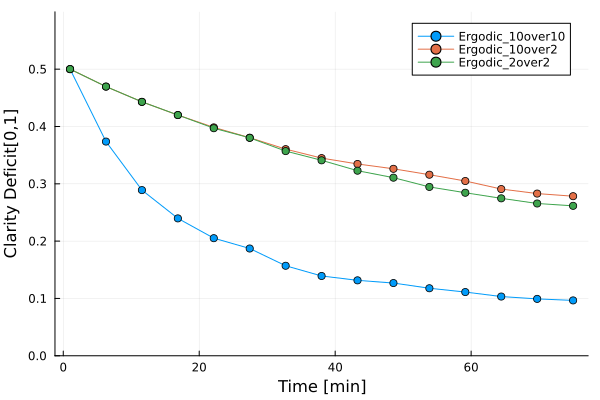

In [39]:
# plot(res_ergo.w_hat_ts, mean_deficit_1, marker=:dot)
gr()
plot()
plot!(time, mean_deficit_10_over_10, marker=:dot, label = "Ergodic_10over10")
plot!(time, mean_deficit_10_over_2, marker=:dot, label = "Ergodic_10over2")
plot!(time, mean_deficit_2_over_2, marker=:dot, label = "Ergodic_2over2")
ylabel!("Clarity Deficit[0,1]")
xlabel!("Time [min]")
ylims!(0., 0.6)

In [22]:
# Define lawn dimensions (length and width) in km
lawn_length = 25.0
lawn_width = 10.0

# Define the top speed of the robot in km/minute
top_speed = 1.8

# Define the sampling interval in minutes
sampling_interval = 5.0 / 60.0

# Define the total number of points
total_points = 2000

# Define a fixed mowing width in km
mowing_width = 4.0

lawn_traj =  TrajectoryLibrary.generate_smooth_lawnmower_path(lawn_length, lawn_width, mowing_width, top_speed,sampling_interval, total_points);
@show size(lawn_traj,1)

size(lawn_traj, 1) = 836


836

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
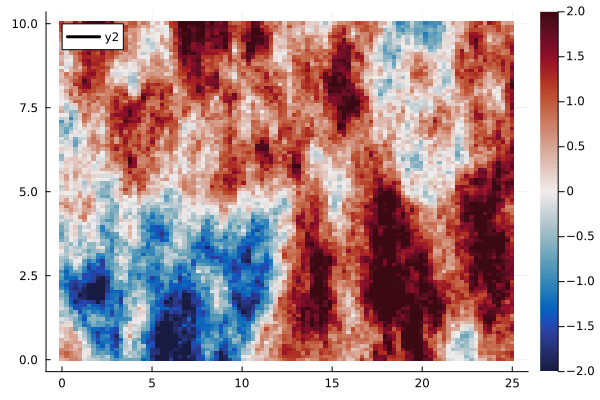

In [23]:
gr()
@gif for n = Int.(floor.(range(1, length(lawn_traj), length=420)))
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
    for i=1:length(x0s)
        x = [r[i][1] for r in lawn_traj[1:n]]
        y = [r[i][2] for r in lawn_traj[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
end

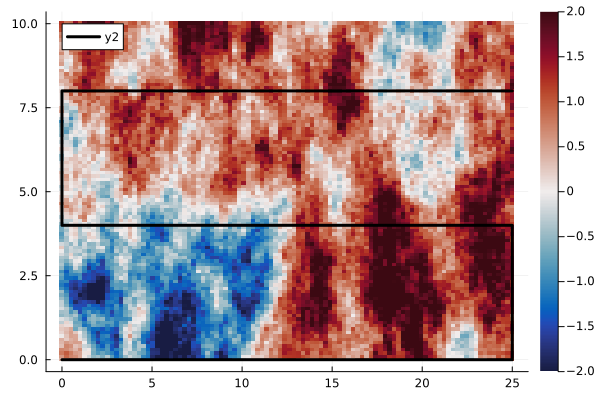

In [24]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
for i=1:1
    x = [r[i][1] for r in lawn_traj]
    y = [r[i][2] for r in lawn_traj]
    plot!(x, y, linewidth=3, color=:black)
end
plot!()

In [25]:
@time res_lawn =  SimulatorSpatial.simulate_prerec_traj(ts, lawn_traj; 
    ngpkf_grid=ngpkf_grid, 
    EnvDataSpatial=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Inside prediction of NGP


Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:02:30
Progress:   1%|▌                                        |  ETA: 0:01:15
Progress:   2%|▊                                        |  ETA: 0:00:50
Progress:   2%|█                                        |  ETA: 0:00:37
Progress:   3%|█▎                                       |  ETA: 0:00:29
Progress:   4%|█▌                                       |  ETA: 0:00:24
Progress:   4%|█▊                                       |  ETA: 0:00:21
Progress:   5%|██                                       |  ETA: 0:00:18
Progress:   5%|██▎                                      |  ETA: 0:00:16
Progress:   6%|██▌                                      |  ETA: 0:00:14
Progress:   7%|██▊                                      |  ETA: 0:00:13
Progress:   7%|███                                      |  ETA: 0:00:12


Inside prediction of NGP


Progress:   8%|███▎                                     |  ETA: 0:00:24
Progress:   8%|███▌                                     |  ETA: 0:00:22
Progress:   9%|███▊                                     |  ETA: 0:00:21
Progress:  10%|████                                     |  ETA: 0:00:19
Progress:  10%|████▎                                    |  ETA: 0:00:18
Progress:  11%|████▌                                    |  ETA: 0:00:17
Progress:  11%|████▊                                    |  ETA: 0:00:16
Progress:  12%|█████                                    |  ETA: 0:00:15
Progress:  13%|█████▎                                   |  ETA: 0:00:14
Progress:  13%|█████▌                                   |  ETA: 0:00:13
Progress:  14%|█████▊                                   |  ETA: 0:00:13
Progress:  14%|██████                                   |  ETA: 0:00:12


Inside prediction of NGP


...

Progress:  80%|████████████████████████████████▉        |  ETA: 0:00:02
Progress:  81%|█████████████████████████████████▏       |  ETA: 0:00:01
Progress:  82%|█████████████████████████████████▍       |  ETA: 0:00:01
Progress:  82%|█████████████████████████████████▋       |  ETA: 0:00:01
Progress:  83%|█████████████████████████████████▉       |  ETA: 0:00:01
Progress:  83%|██████████████████████████████████▏      |  ETA: 0:00:01
Progress:  84%|██████████████████████████████████▍      |  ETA: 0:00:01
Progress:  85%|██████████████████████████████████▋      |  ETA: 0:00:01
Progress:  85%|██████████████████████████████████▉      |  ETA: 0:00:01
Progress:  86%|███████████████████████████████████▏     |  ETA: 0:00:01
Progress:  86%|███████████████████████████████████▍     |  ETA: 0:00:01
Progress:  87%|███████████████████████████████████▋     |  ETA: 0:00:01


Inside prediction of NGP


Progress:  88%|███████████████████████████████████▉     |  ETA: 0:00:01
Progress:  88%|████████████████████████████████████▏    |  ETA: 0:00:01
Progress:  89%|████████████████████████████████████▍    |  ETA: 0:00:01
Progress:  89%|████████████████████████████████████▋    |  ETA: 0:00:01
Progress:  90%|████████████████████████████████████▉    |  ETA: 0:00:01
Progress:  91%|█████████████████████████████████████▏   |  ETA: 0:00:01
Progress:  91%|█████████████████████████████████████▍   |  ETA: 0:00:01
Progress:  92%|█████████████████████████████████████▋   |  ETA: 0:00:01
Progress:  92%|█████████████████████████████████████▉   |  ETA: 0:00:01
Progress:  93%|██████████████████████████████████████▏  |  ETA: 0:00:01
Progress:  94%|██████████████████████████████████████▍  |  ETA: 0:00:00
Progress:  94%|██████████████████████████████████████▋  |  ETA: 0:00:00
Progress:  95%|██████████████████████████████████████▉  |  ETA: 0:00:00
Progress:  95%|███████████████████████████████████████▏ |  ETA: 

  9.086972 seconds (6.42 M allocations: 3.214 GiB, 12.34% gc time, 39.48% compilation time)


Main.SimulatorTemp.SimResultPre{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Main.SimulatorTemp.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(0.0:0.08333333333333333:69.0, Vector{SVector{2, Float64}}[[[0.0, 0.0]], [[0.1497005988023952, 0.0]], [[0.2994011976047904, 0.0]], [[0.4491017964071856, 0.0]], [[0.5988023952095808, 0.0]], [[0.7485029940119761, 0.0]], [[0.8982035928143712, 0.0]], [[1.0479041916167664, 0.0]], [[1.1976047904191616, 0.0]], [[1.347305389221557, 0.0]]  …  [[22.604790419161677, 8.0]], [[22.75449101796407, 8.0]], [[22.904191616766468, 8.0]], [[23.05389221556886, 8.0]], [[23.20359281437126, 8.0]], [[23.353293413173652, 8.0]], [[23.50299401197605, 8.0]], [[23.652694610778443, 8.0]], [[23.802395209580837, 8.0]], [[23.952095808383234, 8.0]]], Main.S

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
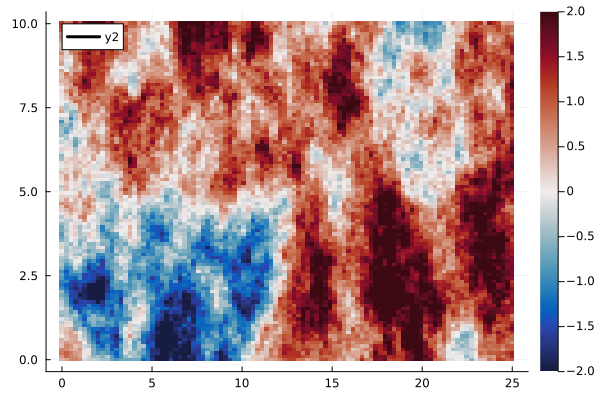

In [26]:
gr()
@gif for n = Int.(floor.(range(1, length(res_lawn.xs), length=420)))
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
    for i=1:1
        x = [r[i][1] for r in res_lawn.xs[1:n]]
        y = [r[i][2] for r in res_lawn.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
end

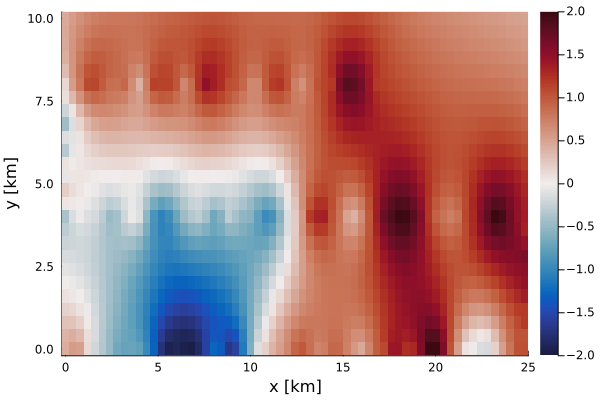

In [27]:
gr()

p2 = heatmap(ngpkf_grid, res_lawn.w_hats[end],colormap=:balance, clims=(-2,2))

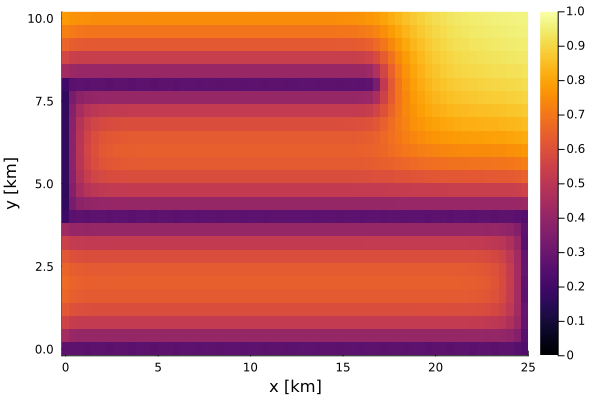

In [28]:
p2 = heatmap(ngpkf_grid, res_lawn.w_hats[end], clims=(0, 1.0), plotstd=true)
# for i=1:length(x0s)
#     x = [r[i][1] for r in res_ergo.xs]
#     y = [r[i][2] for r in res_ergo.xs]
#     plot!(x, y, linewidth=3)
# end
plot!()

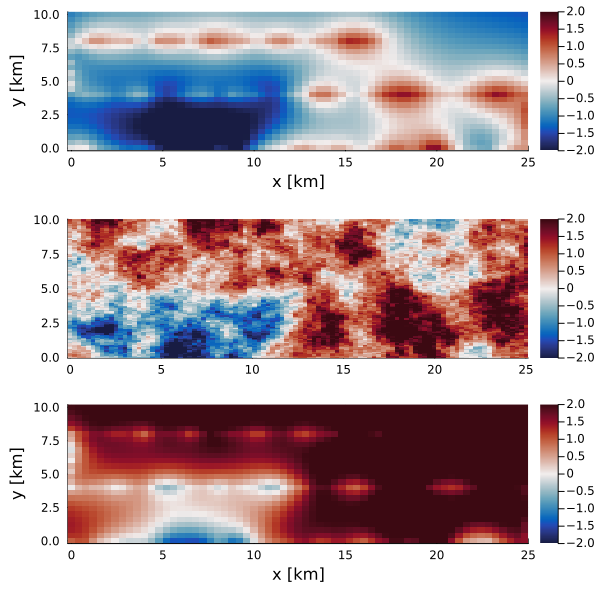

In [39]:
gr()

p1 = heatmap(ngpkf_grid, res_lawn.w_hats[end],colormap=:balance, clims=(-2,2), plot_min=true)
p2 = heatmap(ngpkf_grid, res_lawn.w_hats[end],colormap=:balance, clims=(-2,2), plot_max=true)
p3 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
    
plot(p1, p3, p2, layout = (@layout [a;b; c]), size=[600, 600])

In [40]:
using LinearAlgebra, StatsBase

mean_deficit_ergo = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_ergo.ergo_q_maps]
mean_deficit_lawn = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_lawn.ergo_q_maps]

14-element Vector{Float64}:
 0.5
 0.46472971382828293
 0.4361725718352093
 0.4201983778440714
 0.4171233736871602
 0.41330047275318615
 0.3951267685786091
 0.35508239410271825
 0.31613423778340016
 0.30625664028941113
 0.3027438001305873
 0.29941329131165567
 0.2719318533834649
 0.23942730007365048

In [41]:
ts_ran = range(1, 69, 14)
ti = collect(ts_ran)

14-element Vector{Float64}:
  1.0
  6.230769230769231
 11.461538461538462
 16.692307692307693
 21.923076923076923
 27.153846153846153
 32.38461538461539
 37.61538461538461
 42.84615384615385
 48.07692307692308
 53.30769230769231
 58.53846153846154
 63.76923076923077
 69.0

┌ Warning: Keyword argument markerstrokestyle not supported with
│ Plots.GRBackend(). Choose from: annotationcolor, annotationfontfamily,
│ annotationfontsize, annotationhalign, annotationrotation, annotations,
│ annotationvalign, arrow, aspectratio, axis, backgroundcolor,
│ backgroundcolorinside, backgroundcoloroutside, backgroundcolorsubplot,
│ barwidth, bins, bottommargin, camera, clims, colorpalette, colorbar,
│ colorbarentry, colorbarscale, colorbartitle, colorbartitlefont,
│ colorbartitlefontcolor, colorbartitlefontrotation, colorbartitlefontsize,
│ connections, contourlabels, discretevalues, fill, fillz, fillalpha,
│ fillcolor, fillrange, fillstyle, flip, fontfamily, fontfamilysubplot,
│ foregroundcolor, foregroundcoloraxis, foregroundcolorborder,
│ foregroundcolorgrid, foregroundcolorsubplot, foregroundcolortext,
│ formatter, framestyle, grid, gridalpha, gridlinewidth, gridstyle, group,
│ guide, guidefont, guidefontcolor, guidefontfamily, guidefonthalign,
│ guidefontrotation, g

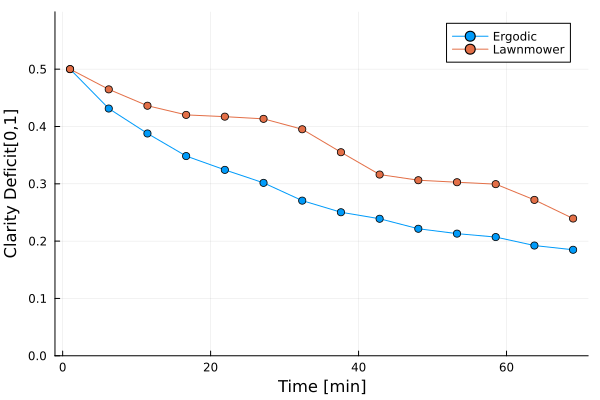

In [42]:
# plot(res_ergo.w_hat_ts, mean_deficit_1, marker=:dot)
gr()
plot()
plot!(ti, mean_deficit_ergo, marker=:dot, label = "Ergodic")
plot!(ti, mean_deficit_lawn, marker=:dot, label = "Lawnmower")
ylabel!("Clarity Deficit[0,1]")
xlabel!("Time [min]")
ylims!(0., 0.6)

In [44]:
min(0, 1)

0